Reading vehicle data...
EOF Reached
Done reading


I0000 00:00:1791910567.045722   59473 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2611 MB memory:  -> device: 0, name: Quadro T1000, pci bus id: 0000:01:00.0, compute capability: 7.5


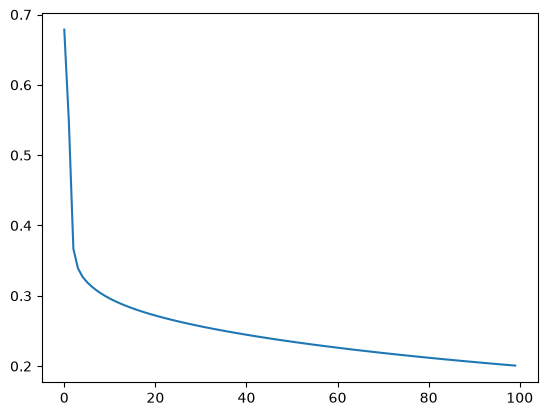

Epoch 100: loss is 0.20075


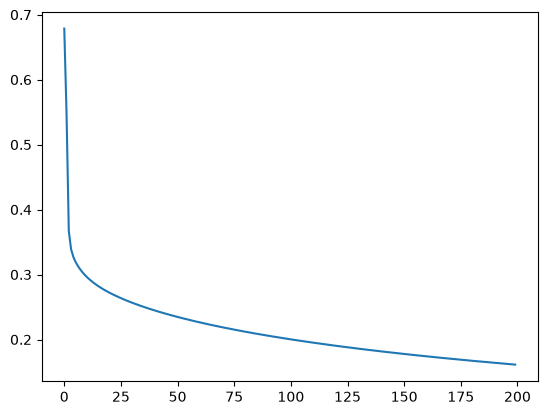

Epoch 200: loss is 0.16139


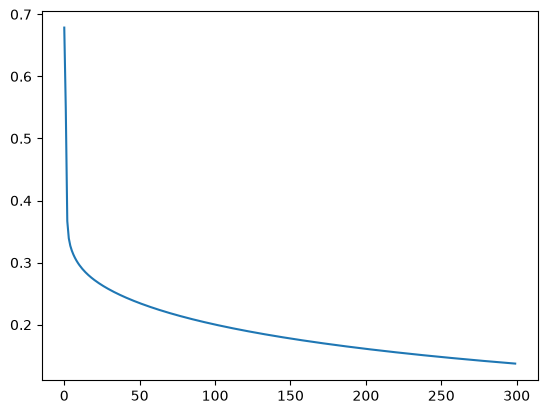

Epoch 300: loss is 0.13735
Precision: 0.770
Recall: 0.827
F1-score: 0.797


In [6]:
"""
This file is for binary classification using TensorFlow
"""

import numpy as np
import matplotlib.pyplot as plt
import tensorflow.compat.v1 as tf
from util import get_vehicle_data
from logistic_np import *

tf.compat.v1.disable_eager_execution()

if __name__ == "__main__":

    np.random.seed(2018)
    tf.set_random_seed(2018)

    # Load data from file
    # Make sure that vehicles.dat is in data/
    train_x, train_y, test_x, test_y = get_vehicle_data()
    num_train = train_x.shape[0]
    num_test = test_x.shape[0]

    #generate_unit_testcase(train_x.copy(), train_y.copy())
    # logistic_unit_test()

    # Normalize our data: choose one of the two methods before training
    #train_x, test_x = normalize_all_pixel(train_x, test_x)
    train_x, test_x = normalize_per_pixel(train_x, test_x)

    # Reshape our data
    # train_x: shape=(2400, 64, 64) -> shape=(2400, 64*64)
    # test_x: shape=(600, 64, 64) -> shape=(600, 64*64)
    train_x = reshape2D(train_x)
    test_x = reshape2D(test_x)

    # Pad 1 as the last feature of train_x and test_x
    train_x = add_one(train_x)
    test_x = add_one(test_x)

    # [TODO 1.11] Create TF placeholders to feed train_x and train_y when training

    train_x = tf.constant(train_x, dtype=tf.float32, name="image_pixel")
    
    train_y = tf.constant(train_y, dtype=tf.float32, name="classifier_out")

    x_test = tf.constant(test_x, dtype=tf.float32, name="test_pixel")

    # [TODO 1.12] Create weights (W) using TF variables

    w = tf.Variable(tf.random.normal(shape = (4097, 1), stddev = 0.01), name="w")

    logits = tf.matmul(train_x, w)

    logits_test = tf.matmul(x_test, w)

    # [TODO 1.13] Create a feed-forward operator

    z = tf.nn.sigmoid(logits, name = "target_function")

    z_test = tf.nn.sigmoid(logits_test, name = "target_function_test")

    pred_test = tf.cast(tf.greater(z_test, 0.5), tf.float32)  

    # [TODO 1.14] Write the cost function

    z = tf.clip_by_value(z, 1e-7, 1 - 1e-7)

    cost = -tf.reduce_sum(train_y * tf.math.log(z) + (1-train_y) * tf.math.log(1-z)) / num_train

    # Define hyper-parameters and train-related parameters
    
    num_epoch = 300
    learning_rate = 0.03
    momentum_rate = 0.9

    # [TODO 1.15] Create an SGD optimizer
    
    optimizer = tf.train.GradientDescentOptimizer(learning_rate=learning_rate)

    train_op = optimizer.minimize(cost)

    # Some meta parameters
    epochs_to_draw = 100
    all_loss = []
    plt.ion()

    # Start training
    init = tf.global_variables_initializer()

    with tf.Session() as sess:

        sess.run(init)

        for e in range(num_epoch):
            #tic = time.perf_counter()
            # [TODO 1.16] Compute loss and update weights here
            
            # Update weights...
            
            _, loss = sess.run([train_op, cost])

            all_loss.append(loss)

            if (e % epochs_to_draw == epochs_to_draw-1):
                plot_loss(all_loss)
                plt.show()
                plt.pause(0.1)
                print("Epoch %d: loss is %.5f" % (e+1, loss))
            #toc = time.perf_counter()
            #print(toc-tic)
        y_hat = sess.run(pred_test)
        test(y_hat, test_y)